<a href="https://colab.research.google.com/github/binary-cpu/port-tracker/blob/main/01_data_pull_and_schema.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Port Traffic: Data Discovery, Contract and First Comparison

**Data snapshot:** through 2026-10-09, accessed 2026-10-17. Source: UN Global Platform; IMF PortWatch.

## A. Locate the Data and Inspect the Fields

In [2]:
import requests, pandas as pd

# We will use the daily ports data feature service address directly
root = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer"
print("service:", root)

info = requests.get(root, params={"f": "json"}, timeout=60).json()
ids = [x["id"] for x in (info.get("layers") or []) + (info.get("tables") or [])] or [0]
url = f"{root}/{ids[0]}"
meta = requests.get(url, params={"f": "json"}, timeout=60).json()
fields = pd.DataFrame([{"name": f["name"], "type": f["type"].replace("esriFieldType", "")} for f in meta.get("fields", [])])
print("layer id:", ids[0], "| fields:", len(fields))

q = f"{url}/query"
n = requests.get(q, params={"where": "1=1", "returnCountOnly": "true", "f": "json"}, timeout=120).json().get("count")

def edge(order):
    r = requests.get(q, params={"where": "1=1", "outFields": "date", "orderByFields": f"date {order}", "resultRecordCount": 1, "returnGeometry": "false", "f": "json"}, timeout=120).json()
    if "features" in r and r["features"]:
        return pd.to_datetime(r["features"][0]["attributes"]["date"]).date()
    return None

print("rows:", f"{n:,}", "| first day:", edge("ASC"), "| last day:", edge("DESC"))

# Fall back to sorting by ObjectId DESC instead of date DESC because sorting on other attributes is restricted
s = requests.get(q, params={"where": "1=1", "outFields": "*", "orderByFields": "ObjectId DESC", "resultRecordCount": 5, "returnGeometry": "false", "f": "json"}, timeout=120).json()
if "features" in s:
    sample = pd.DataFrame([f["attributes"] for f in s.get("features", [])])
    if "date" in sample:
        sample["date"] = pd.to_datetime(sample["date"])
    print(sample.iloc[:, :8].to_string(index=False))
else:
    print("Query failed or returned no features:", s)
fields

service: https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer
layer id: 0 | fields: 30
rows: 5,862,535 | first day: 2019-01-01 | last day: 2026-10-09
      date  year  month  day   portid               portname country ISO3
2026-10-09  2026     10    9 port2508 Zhangzhou LNG Terminal   China  CHN
2026-10-08  2026     10    8 port2508 Zhangzhou LNG Terminal   China  CHN
2026-10-07  2026     10    7 port2508 Zhangzhou LNG Terminal   China  CHN
2026-10-06  2026     10    6 port2508 Zhangzhou LNG Terminal   China  CHN
2026-10-05  2026     10    5 port2508 Zhangzhou LNG Terminal   China  CHN


,name,type
0,date,DateOnly
1,year,Integer
2,month,Integer
3,day,Integer
4,portid,String
5,portname,String
6,country,String
7,ISO3,String
8,portcalls_container,Integer
9,portcalls_dry_bulk,Integer


## B. Test Which Queries the Service Accepts

In [5]:
import requests, pandas as pd, json
root = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer"
q = f"{root}/0/query"
BASE = {"returnGeometry": "false", "f": "json"}
FIELDS = "portid,portname,country,ISO3,date,year,month,portcalls,portcalls_container,portcalls_tanker,import,export"
SUM = json.dumps([{"statisticType": "sum", "onStatisticField": "portcalls", "outStatisticFieldName": "calls"}])
TESTS = {
 "1 all fields, no sorting":            {"where": "1=1", "outFields": "*", "resultRecordCount": 3},
 "2 chosen fields, sorted by date":     {"where": "1=1", "outFields": FIELDS, "orderByFields": "date DESC", "resultRecordCount": 3},
 "3 filter by year and month numbers":  {"where": "year = 2026 AND month = 9", "outFields": FIELDS, "resultRecordCount": 3},
 "4 filter by date text":               {"where": "date >= '2026-10-01'", "outFields": FIELDS, "resultRecordCount": 3},
 "5 filter with DATE keyword":          {"where": "date >= DATE '2026-10-01'", "outFields": FIELDS, "resultRecordCount": 3},
 "6 total calls per port, Sep 2026":    {"where": "year = 2026 AND month = 9", "groupByFieldsForStatistics": "portid", "outStatistics": SUM, "resultRecordCount": 3},
 "7 total calls per month, all ports":  {"where": "1=1", "groupByFieldsForStatistics": "year,month", "outStatistics": SUM, "orderByFields": "year,month", "resultRecordCount": 3},
}
for name, p in TESTS.items():
    try:
        r = requests.get(q, params={**BASE, **p}, timeout=180).json()
        if "error" in r: print(f"FAIL  {name}: {r['error'].get('message')} {r['error'].get('details')}"); continue
        feats = r.get("features", [])
        print(f"OK    {name}: {len(feats)} rows | first: {json.dumps(feats[0]['attributes'])[:210] if feats else None}")
    except Exception as e:
        print(f"FAIL  {name}: {type(e).__name__}: {str(e)[:150]}")

OK    1 all fields, no sorting: 3 rows | first: {"date": "2019-01-01", "year": 2019, "month": 1, "day": 1, "portid": "port1325", "portname": "Tsuruga", "country": "Japan", "ISO3": "JPN", "portcalls_container": 0, "portcalls_dry_bulk": 0, "portcalls_general_c
FAIL  2 chosen fields, sorted by date: Cannot perform query. Invalid query parameters. ['Unable to perform query. Please check your parameters.']
OK    3 filter by year and month numbers: 3 rows | first: {"portid": "port1325", "portname": "Tsuruga", "country": "Japan", "ISO3": "JPN", "date": "2026-09-01", "year": 2026, "month": 9, "portcalls": 1, "portcalls_container": 0, "portcalls_tanker": 0, "import": 85549,
OK    4 filter by date text: 3 rows | first: {"portid": "port1325", "portname": "Tsuruga", "country": "Japan", "ISO3": "JPN", "date": "2026-10-01", "year": 2026, "month": 10, "portcalls": 1, "portcalls_container": 0, "portcalls_tanker": 0, "import": 3036,
OK    5 filter with DATE keyword: 3 rows | first: {"portid": "port1325

## C. Test Paging, Totals and Port Counts

In [6]:
import requests, pandas as pd, json
root = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer"
q = f"{root}/0/query"
BASE = {"returnGeometry": "false", "f": "json"}
SUM = json.dumps([{"statisticType": "sum", "onStatisticField": "portcalls", "outStatisticFieldName": "calls"}])
meta = requests.get(f"{root}/0", params={"f": "json"}, timeout=60).json()
adv = meta.get("advancedQueryCapabilities", {})
print("maxRecordCount:", meta.get("maxRecordCount"), "| pagination:", adv.get("supportsPagination"), "| statistics:", adv.get("supportsStatistics"), "| orderBy:", adv.get("supportsOrderBy"))
CH = "portid,portname,country,date,portcalls"
TESTS = {
 "a distinct port count":        {"where": "1=1", "outFields": "portid", "returnDistinctValues": "true", "returnCountOnly": "true"},
 "b ids not starting with port": {"where": "portid NOT LIKE 'port%'", "outFields": "portid,portname,country", "returnDistinctValues": "true", "resultRecordCount": 15},
 "c month totals, no sorting":   {"where": "1=1", "groupByFieldsForStatistics": "year,month", "outStatistics": SUM, "resultRecordCount": 5},
 "d month totals for one year":  {"where": "year = 2025", "groupByFieldsForStatistics": "month", "outStatistics": SUM, "resultRecordCount": 12},
 "e per-port totals, page 2":    {"where": "year = 2026 AND month = 9", "groupByFieldsForStatistics": "portid", "outStatistics": SUM, "orderByFields": "portid", "resultOffset": 1000, "resultRecordCount": 1000},
 "f sort by ObjectId":           {"where": "year = 2026 AND month = 9", "outFields": CH, "orderByFields": "ObjectId", "resultRecordCount": 3},
 "g sort by date, chosen fields": {"where": "year = 2026 AND month = 9", "outFields": CH, "orderByFields": "date ASC", "resultRecordCount": 3},
}
for name, p in TESTS.items():
    try:
        r = requests.get(q, params={**BASE, **p}, timeout=180).json()
        if "error" in r: print(f"FAIL  {name}: {r['error'].get('message')} {r['error'].get('details')}"); continue
        if "count" in r: print(f"OK    {name}: count = {r['count']:,}"); continue
        feats = r.get("features", [])
        sample = [f["attributes"] for f in feats[:15]] if name.startswith("b") else (json.dumps(feats[0]["attributes"])[:160] if feats else None)
        print(f"OK    {name}: {len(feats)} rows | {sample}")
    except Exception as e:
        print(f"FAIL  {name}: {type(e).__name__}: {str(e)[:150]}")

maxRecordCount: 1000 | pagination: True | statistics: True | orderBy: True
OK    a distinct port count: count = 2,065
FAIL  b ids not starting with port: Cannot perform query. Invalid query parameters. ['Unable to perform query. Please check your parameters.']
OK    c month totals, no sorting: 5 rows | {"calls": 144837, "year": 2019, "month": 1}
OK    d month totals for one year: 12 rows | {"calls": 150102, "month": 1}
OK    e per-port totals, page 2: 1000 rows | {"calls": 42, "portid": "port2262"}
OK    f sort by ObjectId: 3 rows | {"portid": "port1325", "portname": "Tsuruga", "country": "Japan", "date": "2026-09-01", "portcalls": 1}
OK    g sort by date, chosen fields: 3 rows | {"portid": "port1325", "portname": "Tsuruga", "country": "Japan", "date": "2026-09-01", "portcalls": 1}


## D. What the Service Accepts and Rejects

**What the service accepts:** page size 1,000 rows with paging; filtering by year and month numbers or by date text; server-side totals grouped by port or by year and month. **What it rejects:** sorting the whole table without a filter, grouping by year and month together while sorting, and a NOT LIKE filter. **Rule used from here:** filter before sorting, sort small results in Python.

## E. Data Contract

**Question:** Which ports gained or lost the most ship traffic compared with the same period a year earlier, and does the pattern differ by ship type or region?

**Unit:** one port on one day (a count of ship calls observed by AIS); 2,065 ports, 2019-01-01 to the latest published day.

**Headline measure:** port calls, which are counts. Import and export volumes are not used for headline claims, because they are preliminary estimates.

**Comparison:** the latest 28 days against the same 28 days 364 days earlier, which keeps weekdays aligned and removes the seasonal pattern.

**Minimum volume rule:** a port must have at least 50 calls in the baseline window to be ranked, to avoid percentage changes from tiny numbers. Sensitivity to this rule will be tested.

**Limits:** counts are AIS-observed; ports with few calls are noisy; the data lags by about a week; a port is an area defined by the source, so very small or unusual entries may not be ordinary ports.

## F. Retrieve Ports, Check Totals and Compare Periods

In [3]:
import requests, json, pandas as pd
ROOT = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer"
Q = f"{ROOT}/0/query"
TYPES = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]

def query(params):
    r = requests.get(Q, params={"returnGeometry": "false", "f": "json", **params}, timeout=180).json()
    if "error" in r:
        raise RuntimeError(r["error"])
    return r

def fetch_pages(params, page=1000):
    rows, off = [], 0
    while True:
        feats = query({**params, "resultOffset": off, "resultRecordCount": page}).get("features", [])
        rows += [f["attributes"] for f in feats]
        if len(feats) < page:            # a short page is the last page
            break
        off += page
    return pd.DataFrame(rows)

def to_date(v):
    return pd.to_datetime(v, unit="ms") if isinstance(v, (int, float)) else pd.to_datetime(v)

def last_day():
    f = query({"where": "1=1", "outFields": "date", "orderByFields": "date DESC", "resultRecordCount": 1})["features"]
    return to_date(f[0]["attributes"]["date"]).normalize()

def sums(cols):
    return json.dumps([{"statisticType": "sum", "onStatisticField": c, "outStatisticFieldName": f"sum_{c}"} for c in cols])

def port_totals(start, end):
    cols = ["portcalls"] + [f"portcalls_{t}" for t in TYPES]
    d = fetch_pages({"where": f"date >= '{start}' AND date <= '{end}'", "groupByFieldsForStatistics": "portid",
                     "outStatistics": sums(cols), "orderByFields": "portid"})
    return d.rename(columns={f"sum_{c}": c for c in cols})

LAST = last_day()
ports = fetch_pages({"where": f"date >= '{LAST.date()}' AND date <= '{LAST.date()}'", "outFields": "portid,portname,country,ISO3", "orderByFields": "ObjectId"})
print("last day:", LAST.date(), "| ports listed:", len(ports))

# check totals a second way: one full month, per-port sums vs the service's own monthly total
per_port = port_totals("2025-09-01", "2025-09-30")["portcalls"].sum()
# Fixed: Removed 'groupByFieldsForStatistics' as the server restricts grouping by temporal columns
monthly = query({"where": "year = 2025 AND month = 9", "outStatistics": sums(["portcalls"])})["features"][0]["attributes"]["sum_portcalls"]
print("Sep 2025 port calls: sum of per-port totals =", int(per_port), "| service monthly total =", int(monthly), "| match:", int(per_port) == int(monthly))

# recent 28 days vs the same 28 days one year (364 days) earlier
r_end, r_start = LAST, LAST - pd.Timedelta(days=27)
b_end, b_start = r_end - pd.Timedelta(days=364), r_start - pd.Timedelta(days=364)
recent, base = port_totals(r_start.date(), r_end.date()), port_totals(b_start.date(), b_end.date())
MIN_BASE = 50
cmp_ = base[["portid", "portcalls"]].merge(recent[["portid", "portcalls"]], on="portid", suffixes=("_base", "_recent")).merge(ports, on="portid", how="left")
cmp_["change"] = cmp_.portcalls_recent - cmp_.portcalls_base
cmp_["pct_change"] = (100 * (cmp_.portcalls_recent / cmp_.portcalls_base - 1)).where(cmp_.portcalls_base > 0).round(1)
ok = cmp_[cmp_.portcalls_base >= MIN_BASE]
print(f"recent {r_start.date()} to {r_end.date()} vs {b_start.date()} to {b_end.date()} | ports: {len(cmp_)} | with at least {MIN_BASE} baseline calls: {len(ok)}")
cols = ["portname", "country", "portcalls_base", "portcalls_recent", "change", "pct_change"]
print("\nBIGGEST DROPS (by calls)"); print(ok.nsmallest(8, "change")[cols].to_string(index=False))
print("\nBIGGEST GAINS (by calls)"); print(ok.nlargest(8, "change")[cols].to_string(index=False))

last day: 2026-10-09 | ports listed: 2065
Sep 2025 port calls: sum of per-port totals = 151605 | service monthly total = 151605 | match: True
recent 2026-09-12 to 2026-10-09 vs 2025-09-13 to 2025-10-10 | ports: 2065 | with at least 50 baseline calls: 611

BIGGEST DROPS (by calls)
              portname              country  portcalls_base  portcalls_recent  change  pct_change
              Shanghai                China            3375              2204   -1171       -34.7
Bandar-E Pars Terminal                 Iran             634                19    -615       -97.0
             Jebel Ali United Arab Emirates             720               126    -594       -82.5
                 Kerch              Ukraine             438                 0    -438      -100.0
             Singapore            Singapore            3599              3289    -310        -8.6
                Ningbo                China            1637              1345    -292       -17.8
          Khalifa Port United Ara

**Reading the first comparison (28 days to 2026-10-09 against the same 28 days a year earlier).** Of 2,065 ports, 611 have at least 50 baseline calls and are ranked. The biggest drops by calls are Shanghai (-1,171, -34.7%), Bandar-E Pars Terminal in Iran (-615, -97.0%), Jebel Ali (-594, -82.5%), Kerch (-438, -100%) and Khalifa Port (-230, -79.3%); the biggest gains are Mumbai-Jawaharlal Nehru (+427, +159.9%), Ulsan (+395, +70.9%) and Cai Mep (+221, +96.5%). Two of the largest drops are Persian Gulf ports, which is consistent with the Hormuz pattern in the chokepoint project, but this comparison does not show why calls changed. Shanghai's drop and Kerch's zero are unverified and are examined in Section G before any interpretation.

## G. Investigate the Biggest Movers

all 2065 ports: 139,526 calls in the baseline window, 132,708 in the recent window (-4.9%)
ranked ports (611): 204 up, 402 down, 5 unchanged

Calls per 7-day block (oldest on the left; the latest block is on the right)
                                       portname                   country group  wk-11  wk-10  wk-9  wk-8  wk-7  wk-6  wk-5  wk-4  wk-3  wk-2  wk-1  latest  zero_days_last28
portid                                                                                                                                                                       
port1188                               Shanghai                     China  drop    720    642   595   365   698   479   736   616   582   595   527     500                 0
port105                  Bandar-E Pars Terminal                      Iran  drop      3      3     1     3     3     5     5     5     5     5     6       3                16
port744                               Jebel Ali      United Arab Emirates  drop     3

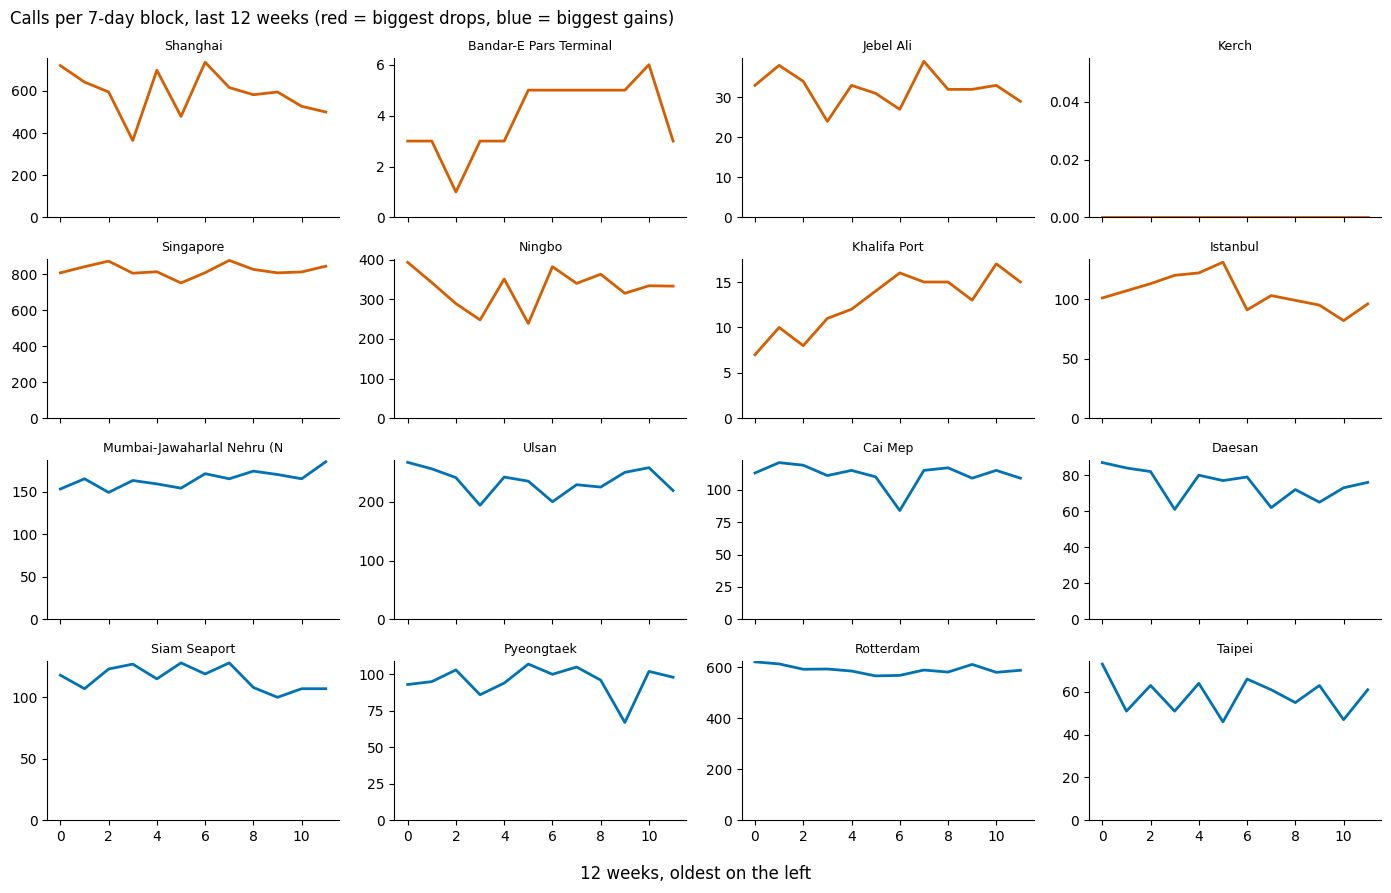

In [3]:
import matplotlib.pyplot as plt

# overall picture first
tot_b, tot_r = cmp_.portcalls_base.sum(), cmp_.portcalls_recent.sum()
print(f"all {len(cmp_)} ports: {tot_b:,} calls in the baseline window, {tot_r:,} in the recent window ({100 * (tot_r / tot_b - 1):+.1f}%)")
print(f"ranked ports ({len(ok)}): {int((ok.change > 0).sum())} up, {int((ok.change < 0).sum())} down, {int((ok.change == 0).sum())} unchanged")

# daily calls for the 16 biggest movers, last 12 weeks, grouped into 7-day blocks ending on the last day
movers = pd.concat([ok.nsmallest(8, "change").assign(group="drop"), ok.nlargest(8, "change").assign(group="gain")])
in_list = ",".join(f"'{p}'" for p in movers.portid)
since = (LAST - pd.Timedelta(days=83)).date()
d = fetch_pages({"where": f"portid IN ({in_list}) AND date >= '{since}'", "outFields": "portid,date,portcalls", "orderByFields": "ObjectId"})
d["date"] = d["date"].map(to_date)
d["block"] = (LAST - d["date"]).dt.days // 7                     # 0 = the latest 7 days
wk = d.pivot_table(index="portid", columns="block", values="portcalls", aggfunc="sum").fillna(0).astype(int)
wk = wk[sorted(wk.columns, reverse=True)]
wk.columns = [f"wk-{c}" if c else "latest" for c in wk.columns]
zero = d[d["date"] > LAST - pd.Timedelta(days=28)].groupby("portid")["portcalls"].apply(lambda s: int((s == 0).sum())).rename("zero_days_last28")
view = movers.set_index("portid")[["portname", "country", "group"]].join(wk).join(zero)
print("\nCalls per 7-day block (oldest on the left; the latest block is on the right)")
print(view.to_string())

fig, axes = plt.subplots(4, 4, figsize=(14, 9), sharex=True)
for ax, (pid, row) in zip(axes.ravel(), view.iterrows()):
    vals = row[[c for c in wk.columns]].astype(float).values
    ax.plot(range(len(vals)), vals, color="#D55E00" if row["group"] == "drop" else "#0072B2", linewidth=2)
    ax.set_title(row["portname"][:26], fontsize=9); ax.set_ylim(0, None); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Calls per 7-day block, last 12 weeks (red = biggest drops, blue = biggest gains)", fontsize=12, x=0.01, ha="left")
fig.supxlabel("12 weeks, oldest on the left")
plt.tight_layout(); plt.show()

**Reading the movers (data through 2026-10-09).** Across all 2,065 ports, calls fell 4.9% between the two windows (139,526 to 132,708); of the 611 ranked ports, 402 are down and 204 are up. None of the 16 biggest movers shows a sudden step in the last 12 weeks: each is roughly flat, at a level that already differs from a year earlier, so the changes happened before this window. Jebel Ali and Khalifa Port sit at low levels that began in March 2026 (see Section H), which is consistent with the Hormuz pattern in the chokepoint project but does not show why; Bandar-E Pars Terminal is erratic and is not clean evidence of the same thing. Kerch has zero calls on all 28 days of the recent window, which could be a real stop or a data gap. Singapore appears among the biggest drops by calls because of its size (-8.6%). The biggest gainers also hold steady at higher levels, so the timing and cause of the changes are not yet known.

## H. Date the Changes Using Monthly History

Monthly calls, complete months only (last month shown: 2026-09)

BIGGEST DROPS
             Shanghai  Bandar-E Pars Terminal  Jebel Ali  Kerch  Singapore  Ningbo  Khalifa Port  Istanbul
month_start                                                                                               
2024-10-01       3684                     156        784      0       3757    1736           269       863
2024-11-01       3552                      13        757    131       3720    1711           253       720
2024-12-01       3813                      18        789    243       3826    1842           265       693
2025-01-01       3715                      21        807    194       3829    1804           281       691
2025-02-01       3050                      14        720    134       3411    1492           246       614
2025-03-01       3687                      19        771    258       3858    1739           262       641
2025-04-01       3645                      19        768    193  

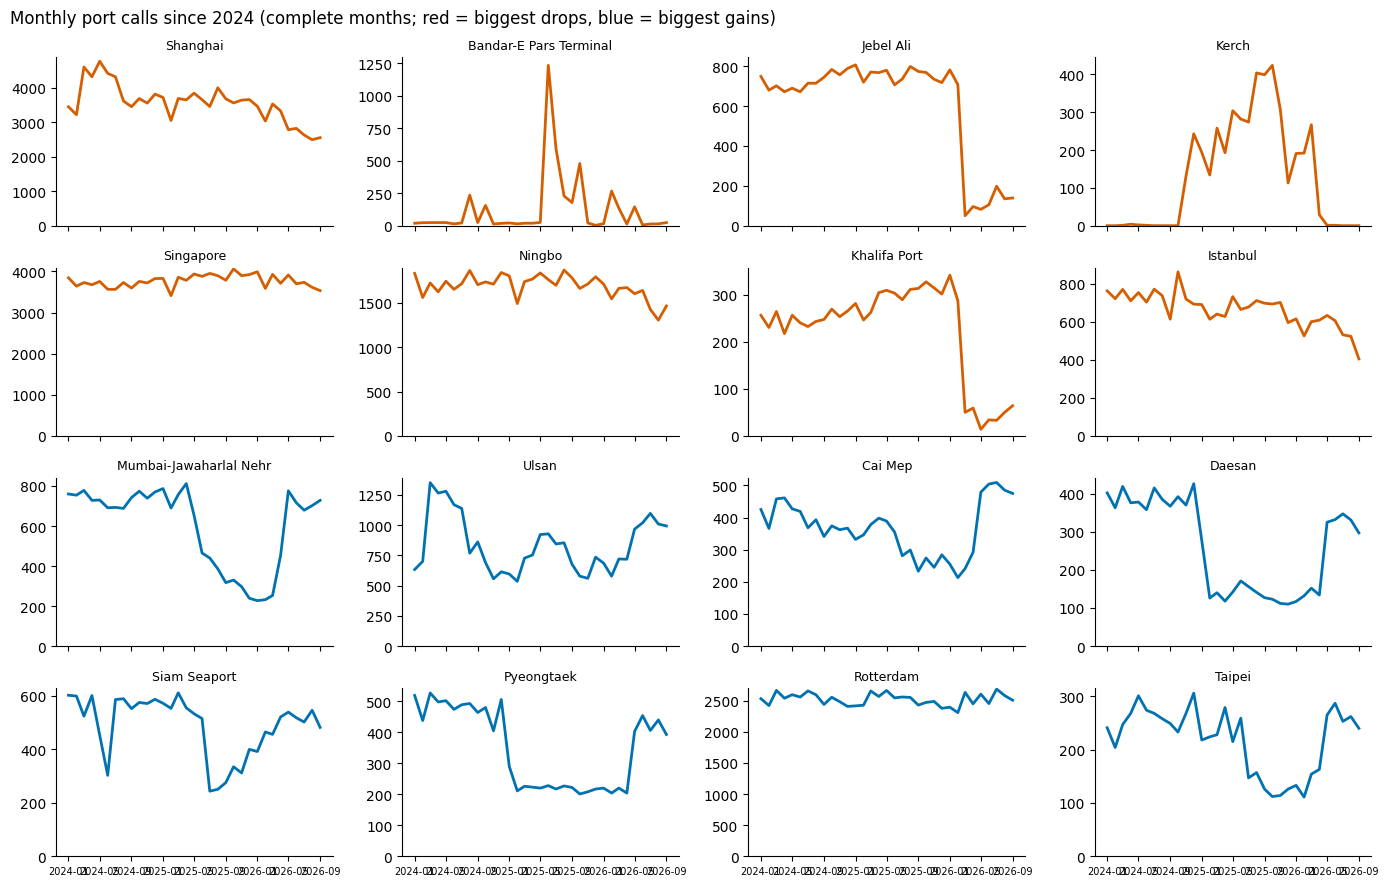

In [10]:
import requests, json, pandas as pd
import matplotlib.pyplot as plt

# Ensure dependent helpers and variables are defined in this session scope
ROOT = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer"
Q = f"{ROOT}/0/query"
TYPES = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]

def query(params):
    r = requests.get(Q, params={"returnGeometry": "false", "f": "json", **params}, timeout=180).json()
    if "error" in r:
        raise RuntimeError(r["error"])
    return r

def fetch_pages(params, page=1000):
    rows, off = [], 0
    while True:
        feats = query({**params, "resultOffset": off, "resultRecordCount": page}).get("features", [])
        rows += [f["attributes"] for f in feats]
        if len(feats) < page:
            break
        off += page
    return pd.DataFrame(rows)

def to_date(v):
    return pd.to_datetime(v, unit="ms") if isinstance(v, (int, float)) else pd.to_datetime(v)

def last_day():
    f = query({"where": "1=1", "outFields": "date", "orderByFields": "date DESC", "resultRecordCount": 1})["features"]
    return to_date(f[0]["attributes"]["date"]).normalize()

def sums(cols):
    return json.dumps([{"statisticType": "sum", "onStatisticField": c, "outStatisticFieldName": f"sum_{c}"} for c in cols])

# Safely resolve LAST and dependent movers data structure if not in global namespace
try:
    _ = LAST
    _ = in_list
    _ = view
except NameError:
    LAST = last_day()
    ports = fetch_pages({"where": f"date >= '{LAST.date()}' AND date <= '{LAST.date()}'", "outFields": "portid,portname,country,ISO3", "orderByFields": "ObjectId"})

    def port_totals(start, end):
        cols = ["portcalls"] + [f"portcalls_{t}" for t in TYPES]
        d = fetch_pages({"where": f"date >= '{start}' AND date <= '{end}'", "groupByFieldsForStatistics": "portid",
                         "outStatistics": sums(cols), "orderByFields": "portid"})
        return d.rename(columns={f"sum_{c}": c for c in cols})

    r_end, r_start = LAST, LAST - pd.Timedelta(days=27)
    b_end, b_start = r_end - pd.Timedelta(days=364), r_start - pd.Timedelta(days=364)
    recent, base = port_totals(r_start.date(), r_end.date()), port_totals(b_start.date(), b_end.date())
    MIN_BASE = 50
    cmp_ = base[["portid", "portcalls"]].merge(recent[["portid", "portcalls"]], on="portid", suffixes=("_base", "_recent")).merge(ports, on="portid", how="left")
    cmp_["change"] = cmp_.portcalls_recent - cmp_.portcalls_base
    cmp_["pct_change"] = (100 * (cmp_.portcalls_recent / cmp_.portcalls_base - 1)).where(cmp_.portcalls_base > 0).round(1)
    ok = cmp_[cmp_.portcalls_base >= MIN_BASE]

    movers = pd.concat([ok.nsmallest(8, "change").assign(group="drop"), ok.nlargest(8, "change").assign(group="gain")])
    in_list = ",".join(f"'{p}'" for p in movers.portid)
    since = (LAST - pd.Timedelta(days=83)).date()
    d = fetch_pages({"where": f"portid IN ({in_list}) AND date >= '{since}'", "outFields": "portid,date,portcalls", "orderByFields": "ObjectId"})
    d["date"] = d["date"].map(to_date)
    d["block"] = (LAST - d["date"]).dt.days // 7
    wk = d.pivot_table(index="portid", columns="block", values="portcalls", aggfunc="sum").fillna(0).astype(int)
    wk = wk[sorted(wk.columns, reverse=True)]
    wk.columns = [f"wk-{c}" if c else "latest" for c in wk.columns]
    zero = d[d["date"] > LAST - pd.Timedelta(days=28)].groupby("portid")["portcalls"].apply(lambda s: int((s == 0).sum())).rename("zero_days_last28")
    view = movers.set_index("portid")[["portname", "country", "group"]].join(wk).join(zero)

# monthly calls since 2024 for the 16 movers (server-side totals; complete months only)
hist = fetch_pages({"where": f"portid IN ({in_list}) AND year >= 2024", "groupByFieldsForStatistics": "portid,year,month",
                    "outStatistics": sums(["portcalls"])}).rename(columns={"sum_portcalls": "calls"})
hist["month_start"] = pd.to_datetime(dict(year=hist.year, month=hist.month, day=1))
complete_to = LAST.replace(day=1)                                   # the month containing the last day is partial
hist = hist[hist.month_start < complete_to]
names = view["portname"].str[:22]
m = hist.pivot(index="month_start", columns="portid", values="calls").fillna(0).astype(int)[list(view.index)]
m.columns = [names[c] for c in m.columns]
print("Monthly calls, complete months only (last month shown:", m.index.max().strftime("%Y-%m") + ")")
print("\nBIGGEST DROPS"); print(m.iloc[:, :8].tail(24).to_string())
print("\nBIGGEST GAINS"); print(m.iloc[:, 8:].tail(24).to_string())

# when did each port change level? reference = average month in Jan-Sep 2025
ref = m.loc["2025-01-01":"2025-09-01"].mean()
cv = (m.loc["2025-01-01":"2025-09-01"].std() / ref).round(2)          # volatility: above 1.0 means very erratic
rows = []
for col, grp in zip(m.columns, view["group"]):
    s = m.loc["2025-10-01":, col]
    past = (s < 0.5 * ref[col]) if grp == "drop" else (s > 1.5 * ref[col])
    sustained = next((s.index[i] for i in range(len(s)) if past.iloc[i:].all()), None)   # first month from which every later month is also past the line
    rows.append({"port": col, "group": grp, "avg_month_2025_Jan_Sep": round(ref[col], 1), "volatility_cv": cv[col], "latest_complete_month": int(m[col].iloc[-1]),
                 "pct_of_reference": round(100 * m[col].iloc[-1] / ref[col], 1) if ref[col] else None,
                 "sustained_from": sustained.strftime("%Y-%m") if sustained is not None else "not sustained"})
timeline = pd.DataFrame(rows); print("\nWhen each level changed (drops: below 50% of reference; gains: above 150%; sustained = stays past the line)"); print(timeline.to_string(index=False))

fig, axes = plt.subplots(4, 4, figsize=(14, 9), sharex=True)
for ax, col, grp in zip(axes.ravel(), m.columns, view["group"]):
    ax.plot(m.index, m[col], color="#D55E00" if grp == "drop" else "#0072B2", linewidth=2)
    ax.set_title(col, fontsize=9); ax.set_ylim(0, None); ax.spines[["top", "right"]].set_visible(False); ax.tick_params(axis="x", labelsize=7)
fig.suptitle("Monthly port calls since 2024 (complete months; red = biggest drops, blue = biggest gains)", fontsize=12, x=0.01, ha="left")
plt.tight_layout(); plt.show()

**Reading the monthly history (complete months to 2026-09).** The year-ago comparison inherits the baseline period: Mumbai-Jawaharlal Nehru's +160% is mostly a recovery from a trough (about 770 calls a month in 2024, 230-330 from mid-2025 to March 2026, about 700 now), and Bandar-E Pars Terminal's -97% reflects bursts in the baseline window (monthly calls mostly 3 to 25, with bursts of 1,233, 590, 228, 178 and 478). Jebel Ali (708 to 50 between February and March 2026) and Khalifa Port (287 to 50) stepped down in March 2026 and have stayed low, consistent with the timing of the Hormuz pattern but not proof of a link. Kerch wound down between March and July 2026 and has had no calls since. Shanghai, Ningbo and Istanbul declined gradually, with no step. Mumbai, Ulsan, Cai Mep, Daesan, Pyeongtaek and Taipei all rose in April-May 2026; a simultaneous step across ports in different countries suggests a common cause that I have not identified.

## I. Test Whether the 2026 Changes Are Broad

all 12 months ready in 0s
12 complete months, 180 countries | world calls per day: min 4,673, max 4,999

BREADTH BY MONTH (calls per day)
             countries_up_15pct  countries_down_15pct  world_calls_per_day
month_start                                                               
2025-10-01                    0                     0                 4928
2025-11-01                    0                     3                 4999
2025-12-01                    0                     4                 4835
2026-01-01                    1                     7                 4673
2026-02-01                    7                     0                 4811
2026-03-01                    2                     7                 4787
2026-04-01                    4                     1                 4791
2026-05-01                    6                     1                 4918
2026-06-01                    1                     2                 4971
2026-07-01                    1      

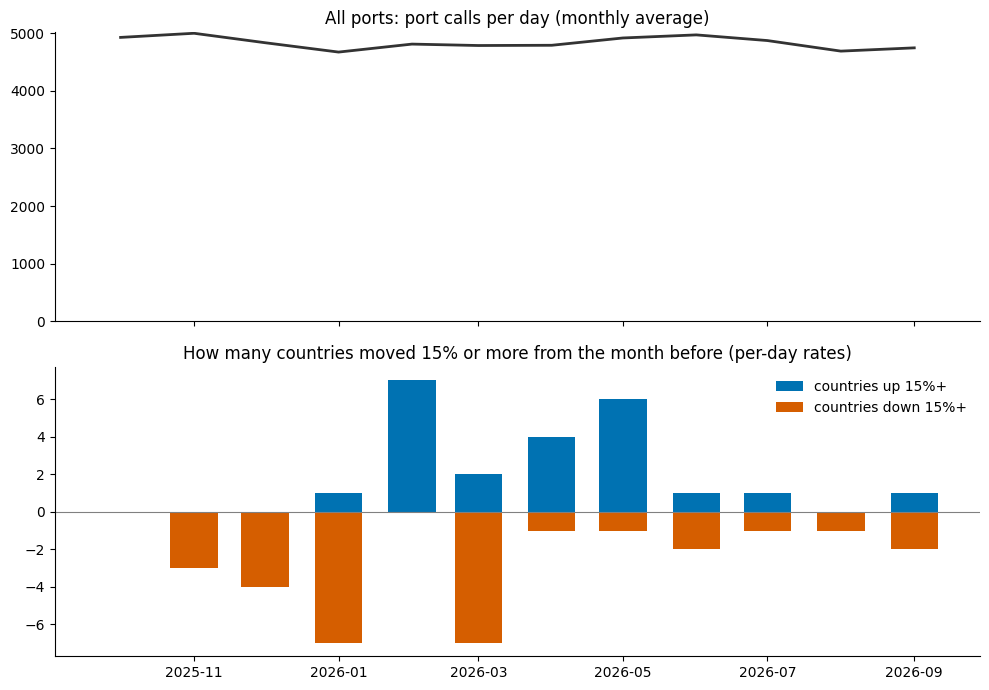

In [5]:
import time
from concurrent.futures import ThreadPoolExecutor

# the last 12 complete months, fetched four at a time, with progress and a cache so a re-run only fetches what is missing
months = pd.period_range(LAST.to_period("M") - 12, LAST.to_period("M") - 1, freq="M")
try:
    cache
except NameError:
    cache = {}

def month_totals(p):
    if (p.year, p.month) in cache:
        return p
    t0 = time.time()
    t = fetch_pages({"where": f"year = {p.year} AND month = {p.month}", "groupByFieldsForStatistics": "ISO3", "outStatistics": sums(["portcalls"])})
    t["month_start"] = p.to_timestamp(); cache[(p.year, p.month)] = t
    print(f"{p} done in {time.time() - t0:.0f}s ({len(t)} countries)", flush=True)
    return p

t_all = time.time()
with ThreadPoolExecutor(max_workers=4) as ex:
    list(ex.map(month_totals, months))
print(f"all {len(months)} months ready in {time.time() - t_all:.0f}s")
cm = pd.concat([cache[(p.year, p.month)] for p in months]).rename(columns={"sum_portcalls": "calls"})

cname = ports.drop_duplicates("ISO3").set_index("ISO3")["country"]
piv = cm.pivot(index="month_start", columns="ISO3", values="calls").fillna(0)
rate = piv.div(piv.index.days_in_month, axis=0)                  # calls PER DAY, so months of different length compare fairly
world = rate.sum(axis=1)
print(f"{len(months)} complete months, {rate.shape[1]} countries | world calls per day: min {world.min():,.0f}, max {world.max():,.0f}")

# breadth: in each month, how many countries (with at least 10 calls a day the month before) moved by 15% or more?
prev = rate.shift(1); chg = rate / prev - 1
big = prev >= 10
up, down = ((chg >= 0.15) & big).sum(axis=1), ((chg <= -0.15) & big).sum(axis=1)
breadth = pd.DataFrame({"countries_up_15pct": up, "countries_down_15pct": down, "world_calls_per_day": world.round(0).astype(int)})
print("\nBREADTH BY MONTH (calls per day)"); print(breadth.tail(24).to_string())

def movers(month, n=6):
    ts = pd.Timestamp(month)
    t = pd.DataFrame({"country": [cname.get(i, i) for i in rate.columns], "prev_per_day": prev.loc[ts].values.round(1), "now_per_day": rate.loc[ts].values.round(1), "pct": (chg.loc[ts] * 100).round(1).values})
    t = t[t.prev_per_day >= 10]
    return t.nlargest(n, "pct"), t.nsmallest(n, "pct")
for month in ("2026-03-01", "2026-05-01"):
    a, b = movers(month); print(f"\n{month[:7]}: biggest rises"); print(a.to_string(index=False)); print(f"{month[:7]}: biggest falls"); print(b.to_string(index=False))

fig, ax = plt.subplots(2, 1, figsize=(10, 7), sharex=True)
ax[0].plot(world.index, world.values, color="#333333", linewidth=2); ax[0].set_ylim(0, None); ax[0].set_title("All ports: port calls per day (monthly average)")
ax[1].bar(up.index, up.values, width=20, color="#0072B2", label="countries up 15%+"); ax[1].bar(down.index, -down.values, width=20, color="#D55E00", label="countries down 15%+")
ax[1].axhline(0, color="gray", linewidth=0.8); ax[1].legend(frameon=False); ax[1].set_title("How many countries moved 15% or more from the month before (per-day rates)")
for a_ in ax: a_.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

**Reading the breadth test (calls per day, complete months to 2026-09).** World port calls per day stayed between 4,673 and 4,999 across the last 12 months, with no step in March or May, so the changes below are redistributions, not a change in the total. In March 2026 the biggest falls were all Gulf-region countries: the United Arab Emirates (-79.8%, from 84.1 to 17.0 calls a day), Qatar (-74.3%), Iraq (-63.6%), Iran (-31.4%), Oman (-27.0%) and Saudi Arabia (-27.0%), while the biggest rises were small. This is consistent with the timing of the Hormuz pattern in the chokepoint project but does not show why. In May 2026 only six countries rose by 15% or more (Argentina, India, Korea, the Philippines, Taiwan and Greece), four of them in Asia, while China fell 10.8%; I have not established whether this is real traffic shifting or a change in how the data are collected. Monthly counts were converted to calls per day because months differ in length.

## J. Compare Gulf-Region Countries With the Rest of the World, and Test the May 2026 Rise by Ship Type

countries counted as Gulf-region: ['ARE', 'QAT', 'IRQ', 'IRN', 'KWT', 'BHR', 'SAU', 'OMN']
             gulf_per_day  rest_per_day  gulf_index  rest_index
month_start                                                    
2025-10-01          184.2        4743.4       111.0       101.3
2025-11-01          163.4        4835.8        98.4       103.3
2025-12-01          144.4        4690.7        87.0       100.2
2026-01-01          155.5        4517.4        93.7        96.5
2026-02-01          182.4        4629.0       109.9        98.8
2026-03-01           73.0        4713.8        44.0       100.7
2026-04-01           80.9        4710.0        48.8       100.6
2026-05-01           80.9        4836.7        48.7       103.3
2026-06-01           93.0        4878.2        56.0       104.2
2026-07-01           97.3        4775.5        58.6       102.0
2026-08-01           80.3        4609.3        48.3        98.4
2026-09-01           78.6        4667.6        47.4        99.7


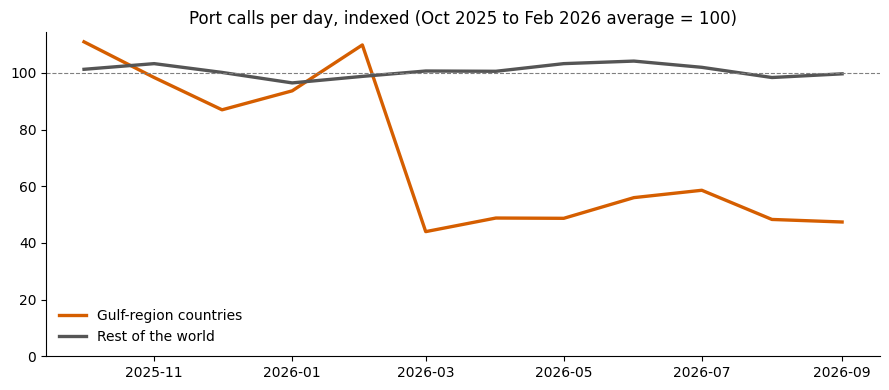


April to May 2026, % change in calls per day, by ship type
ship_type    container  dry_bulk  general_cargo  roro  tanker
country                                                      
China             -6.2     -10.8          -10.7  -1.2   -17.7
India             33.5      31.6          103.1  40.5    40.2
Korea             13.4      44.9           39.2  50.3    42.8
Philippines       17.0      24.1           22.0  61.3    22.4
Taiwan            12.6      25.6            3.3  46.8    48.6

May minus April, calls per day
ship_type    container  dry_bulk  general_cargo  roro  tanker
country                                                      
China            -14.7     -23.8           -9.4  -0.2   -31.1
India              7.7       7.7           11.4   0.5     7.6
Korea              6.4       5.2           12.5   4.6    20.7
Philippines        2.5       0.7            3.3   0.9     2.9
Taiwan             4.0       2.3            0.3   0.4     4.1


In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import requests
import json
from concurrent.futures import ThreadPoolExecutor

# Ensure dependent helpers and variables are defined in this session scope
ROOT = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer"
Q = f"{ROOT}/0/query"
TYPES = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]

def query(params):
    r = requests.get(Q, params={"returnGeometry": "false", "f": "json", **params}, timeout=180).json()
    if "error" in r:
        raise RuntimeError(r["error"])
    return r

def fetch_pages(params, page=1000):
    rows, off = [], 0
    while True:
        feats = query({**params, "resultOffset": off, "resultRecordCount": page}).get("features", [])
        rows += [f["attributes"] for f in feats]
        if len(feats) < page:
            break
        off += page
    return pd.DataFrame(rows)

def to_date(v):
    return pd.to_datetime(v, unit="ms") if isinstance(v, (int, float)) else pd.to_datetime(v)

def last_day():
    f = query({"where": "1=1", "outFields": "date", "orderByFields": "date DESC", "resultRecordCount": 1})["features"]
    return to_date(f[0]["attributes"]["date"]).normalize()

def sums(cols):
    return json.dumps([{"statisticType": "sum", "onStatisticField": c, "outStatisticFieldName": f"sum_{c}"} for c in cols])

# Recreate global state if undefined
try:
    _ = rate
    _ = ports
except NameError:
    LAST = last_day()
    ports = fetch_pages({"where": f"date >= '{LAST.date()}' AND date <= '{LAST.date()}'", "outFields": "portid,portname,country,ISO3", "orderByFields": "ObjectId"})

    # Retrieve history to build rate
    months = pd.period_range(LAST.to_period("M") - 12, LAST.to_period("M") - 1, freq="M")
    cache = {}

    def month_totals(p):
        t = fetch_pages({"where": f"year = {p.year} AND month = {p.month}", "groupByFieldsForStatistics": "ISO3", "outStatistics": sums(["portcalls"])})
        t["month_start"] = p.to_timestamp()
        cache[(p.year, p.month)] = t
        return p

    with ThreadPoolExecutor(max_workers=4) as ex:
        list(ex.map(month_totals, months))

    cm = pd.concat([cache[(p.year, p.month)] for p in months]).rename(columns={"sum_portcalls": "calls"})
    piv = cm.pivot(index="month_start", columns="ISO3", values="calls").fillna(0)
    rate = piv.div(piv.index.days_in_month, axis=0)

GULF = ["ARE", "QAT", "IRQ", "IRN", "KWT", "BHR", "SAU", "OMN"]      # Gulf-region countries; approximate, because some of their ports are outside the Gulf
g = [c for c in GULF if c in rate.columns]
gulf, rest = rate[g].sum(axis=1), rate.drop(columns=g).sum(axis=1)
ref = slice("2025-10-01", "2026-02-01")
gr = pd.DataFrame({"gulf_per_day": gulf.round(1), "rest_per_day": rest.round(1),
                   "gulf_index": (100 * gulf / gulf.loc[ref].mean()).round(1), "rest_index": (100 * rest / rest.loc[ref].mean()).round(1)})
print("countries counted as Gulf-region:", g); print(gr.to_string())
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(gr.index, gr.gulf_index, color="#D55E00", linewidth=2.4, label="Gulf-region countries"); ax.plot(gr.index, gr.rest_index, color="#555555", linewidth=2.4, label="Rest of the world")
ax.axhline(100, color="gray", linewidth=0.8, linestyle="--"); ax.set_ylim(0, None); ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Port calls per day, indexed (Oct 2025 to Feb 2026 average = 100)"); plt.tight_layout(); plt.show()

FOCUS = {"IND": "India", "KOR": "Korea", "PHL": "Philippines", "TWN": "Taiwan", "CHN": "China"}
TYPE_COLS = [f"portcalls_{t}" for t in TYPES]
iso_list = ",".join(f"'{c}'" for c in FOCUS)
t = fetch_pages({"where": f"year = 2026 AND month IN (4, 5) AND ISO3 IN ({iso_list})", "groupByFieldsForStatistics": "ISO3,month", "outStatistics": sums(TYPE_COLS)})
t = t.rename(columns={f"sum_{c}": c.replace("portcalls_", "") for c in TYPE_COLS})
rows = []
for iso, name in FOCUS.items():
    for ty in TYPES:
        a = t[(t.ISO3 == iso) & (t.month == 4)][ty].sum() / 30; b = t[(t.ISO3 == iso) & (t.month == 5)][ty].sum() / 31
        rows.append({"country": name, "ship_type": ty, "apr_per_day": round(a, 1), "may_per_day": round(b, 1), "pct_change": round(100 * (b / a - 1), 1) if a else None})
k = pd.DataFrame(rows)
print("\nApril to May 2026, % change in calls per day, by ship type"); print(k.pivot(index="country", columns="ship_type", values="pct_change").to_string())
print("\nMay minus April, calls per day"); print(k.assign(diff=(k.may_per_day - k.apr_per_day).round(1)).pivot(index="country", columns="ship_type", values="diff").to_string())

**Reading the Gulf comparison (calls per day, complete months to 2026-09).** The eight Gulf-region countries (an approximate grouping, since some of their ports lie outside the Gulf) ran at 144 to 184 calls a day from October 2025 to February 2026, fell to 73 in March 2026 and have since stayed at 47% to 59% of their October-February average, with a partial recovery in June and July. The rest of the world stayed within about 4% of its own average throughout. The timing matches the Hormuz pattern in the chokepoint project, but both datasets come from the same AIS source and method, so the match is not independent confirmation, and it does not show why traffic changed.

**Reading the ship-type test (April to May 2026, calls per day).** In India, Korea, the Philippines and Taiwan the rise was spread across nearly every ship type (for example India: containers +33.5%, dry bulk +31.6%, tankers +40.2%), while China fell across every type (-1.2% to -17.7%). A rise spread across all ship types is more consistent with a change affecting overall counting or coverage than with a single commodity's trade shifting, but a real change in traffic could also lift every type, so the cause remains unexplained.

## K. Test Whether the Rankings Depend on the Window and the Volume Rule

In [6]:
# how much do the rankings depend on the window length and the minimum-volume rule?

# Ensure recent, base, and helper functions exist in global namespace
try:
    _ = recent
    _ = base
except NameError:
    import pandas as pd
    import requests
    import json

    ROOT = "https://services9.arcgis.com/weJ1QsnbMYJlCHdG/arcgis/rest/services/Daily_Ports_Data/FeatureServer"
    Q = f"{ROOT}/0/query"
    TYPES = ["container", "dry_bulk", "general_cargo", "roro", "tanker"]

    def query(params):
        r = requests.get(Q, params={"returnGeometry": "false", "f": "json", **params}, timeout=180).json()
        if "error" in r:
            raise RuntimeError(r["error"])
        return r

    def fetch_pages(params, page=1000):
        rows, off = [], 0
        while True:
            feats = query({**params, "resultOffset": off, "resultRecordCount": page}).get("features", [])
            rows += [f["attributes"] for f in feats]
            if len(feats) < page:
                break
            off += page
        return pd.DataFrame(rows)

    def sums(cols):
        return json.dumps([{"statisticType": "sum", "onStatisticField": c, "outStatisticFieldName": f"sum_{c}"} for c in cols])

    def to_date(v):
        return pd.to_datetime(v, unit="ms") if isinstance(v, (int, float)) else pd.to_datetime(v)

    def last_day():
        f = query({"where": "1=1", "outFields": "date", "orderByFields": "date DESC", "resultRecordCount": 1})["features"]
        return to_date(f[0]["attributes"]["date"]).normalize()

    def port_totals(start, end):
        cols = ["portcalls"] + [f"portcalls_{t}" for t in TYPES]
        d = fetch_pages({"where": f"date >= '{start}' AND date <= '{end}'", "groupByFieldsForStatistics": "portid",
                         "outStatistics": sums(cols), "orderByFields": "portid"})
        return d.rename(columns={f"sum_{c}": c for c in cols})

    try:
        _ = LAST
    except NameError:
        LAST = last_day()

    try:
        _ = ports
    except NameError:
        ports = fetch_pages({"where": f"date >= '{LAST.date()}' AND date <= '{LAST.date()}'", "outFields": "portid,portname,country,ISO3", "orderByFields": "ObjectId"})

    # Fallback to compute recent and base if they are missing
    r_end, r_start = LAST, LAST - pd.Timedelta(days=27)
    b_end, b_start = r_end - pd.Timedelta(days=364), r_start - pd.Timedelta(days=364)
    recent, base = port_totals(r_start.date(), r_end.date()), port_totals(b_start.date(), b_end.date())

cache90 = {}
def window_tables(days):
    if days == 28:
        return recent, base
    if days not in cache90:
        r_end, r_start = LAST, LAST - pd.Timedelta(days=days - 1)
        b_end, b_start = r_end - pd.Timedelta(days=364), r_start - pd.Timedelta(days=364)
        cache90[days] = (port_totals(r_start.date(), r_end.date()), port_totals(b_start.date(), b_end.date()))
    return cache90[days]

def ranked(days, min_base):
    rec, bas = window_tables(days)
    c = bas[["portid", "portcalls"]].merge(rec[["portid", "portcalls"]], on="portid", suffixes=("_base", "_recent")).merge(ports, on="portid", how="left")
    c["change"] = c.portcalls_recent - c.portcalls_base
    return c[c.portcalls_base >= min_base]

main = ranked(28, 50)
main_drops, main_gains = set(main.nsmallest(10, "change").portname), set(main.nlargest(10, "change").portname)
rows = []
for days, mb in [(28, 20), (28, 50), (28, 200), (90, 50), (90, 150), (90, 600)]:
    r = ranked(days, mb)
    rows.append({"window_days": days, "min_baseline_calls": mb, "ports_ranked": len(r),
                 "drops_shared_with_main": len(set(r.nsmallest(10, "change").portname) & main_drops),
                 "gains_shared_with_main": len(set(r.nlargest(10, "change").portname) & main_gains),
                 "top3_drops": ", ".join(r.nsmallest(3, "change").portname.str[:18])})
pd.DataFrame(rows)

,window_days,min_baseline_calls,ports_ranked,drops_shared_with_main,gains_shared_with_main,top3_drops
0,28,20,1046,10,10,"Shanghai, Bandar-E Pars Term, Jebel Ali"
1,28,50,611,10,10,"Shanghai, Bandar-E Pars Term, Jebel Ali"
2,28,200,152,10,6,"Shanghai, Bandar-E Pars Term, Jebel Ali"
3,90,50,1169,9,8,"Shanghai, Jebel Ali, Kerch"
4,90,150,651,9,9,"Shanghai, Jebel Ali, Kerch"
5,90,600,168,9,6,"Shanghai, Jebel Ali, Kerch"


**Reading the sensitivity test.** The 10 biggest drops by calls are the same 10 ports under every volume rule tested for the 28-day window (minimum 20, 50 and 200 baseline calls) and 9 of the 10 under the 90-day windows. Shanghai ranks first in every setting and Jebel Ali is in the top three in all of them; Bandar-E Pars Terminal is in the top three only for 28-day windows, and Kerch enters the top three for the 90-day windows. The biggest gains are less stable: all 10 are shared at minimums of 20 and 50 baseline calls, but only 6 at a minimum of 200 (28 days) or 600 (90 days), because several are mid-sized ports that drop out when the volume rule rises. The list of biggest drops is robust to these choices, while the list of biggest gains depends on them.

## L. Key Findings and Limitations

**Key findings (snapshot through 2026-10-09)**
- The data form a complete grid: 2,065 ports over 2,839 days is 5,862,535 daily rows (2019-01-01 to 2026-10-09), and per-port totals for September 2025 (151,605 calls) match the service's own monthly total.
- Across all ports, calls fell 4.9% between the latest 28 days and the same days a year earlier (139,526 to 132,708). Of 611 ranked ports (at least 50 baseline calls), 402 are down and 204 are up.
- The biggest drops by calls (Shanghai -1,171, Jebel Ali -594, Kerch -438, Khalifa Port -230) are stable across window lengths and volume rules; the list of biggest gains is less stable.
- The year-ago comparison inherits quirks of the baseline period: Mumbai-Jawaharlal Nehru's +160% is mostly a recovery from a trough, and Bandar-E Pars Terminal's -97% reflects bursts in the baseline window.
- Gulf-region countries (an approximate grouping) fell from 182 calls a day in February 2026 to 73 in March and have stayed at 47% to 59% of their October-February average since April, with Jebel Ali (708 to 50 monthly calls) and Khalifa Port (287 to 50) stepping down in March 2026, while the rest of the world stayed within about 4% of its average. This matches the timing of the Hormuz pattern in the chokepoint project; both come from the same AIS source.
- Kerch wound down between March and July 2026 and has had no calls since July. Shanghai, Ningbo and Istanbul declined gradually; Shanghai is at 70% of its January-September 2025 monthly average.
- Between April and May 2026, calls per day rose in India (+44.5%), Korea (+33.2%), the Philippines (+21.8%) and Taiwan (+19.1%), across nearly every ship type, while China fell 10.8%. The cause is unexplained.

**Limitations**
- Counts are AIS-observed. Ports are areas defined by the source, and some entries (for example ids such as fso0) are not ordinary ports and have not been checked.
- The data lag by about a week (last day 2026-10-09).
- The year-ago comparison depends on what happened a year earlier. Monthly counts in Section H are not adjusted for month length, so changes under about 10% there are not interpretable.
- Grouping Gulf-region countries by country is approximate; port coordinates would allow a precise grouping.
- The agreement with the Hormuz timing is not independent, since both datasets come from the same source and method.
- No change has been linked to outside events, and the import and export volume fields were not used because they are preliminary estimates.